# Chapitre 4 - Exercices 4.1 à 4.5

- **4.1** : problème aux valeurs propres généralisé ;
- **4.2** : LDA et moindres carrés à deux classes ;
- **4.3** : LDA sur les réponses ajustées de la régression sur indicatrices ;
- **4.4** : Newton-Raphson pour la logistique multinomiale ;
- **4.5** : régression logistique sur des données séparables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

## Exercice 4.1 : Problème aux valeurs propres généralisé

**Énoncé.** Montrer comment résoudre le problème
$\max_a a^T\mathbf{B}a$ sous la contrainte $a^T\mathbf{W}a = 1$ en le ramenant à un
problème aux valeurs propres standard. (Ici $\mathbf{B}$ est symétrique semi-définie
positive et $\mathbf{W}$ symétrique définie positive, comme les covariances inter- et
intra-classes de la LDA de rang réduit.)

### Rappels

- **Théorème spectral.** Une matrice symétrique réelle $\mathbf{S}$ s'écrit
  $\mathbf{S} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ avec $\mathbf{U}$ orthogonale (colonnes
  $u_j$ orthonormées) et $\mathbf{D} = \operatorname{diag}(\lambda_1 \ge \dots \ge \lambda_p)$.
- **Racine carrée.** Si $\mathbf{W} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ est définie positive
  ($\lambda_j > 0$), on pose $\mathbf{W}^{1/2} = \mathbf{U}\mathbf{D}^{1/2}\mathbf{U}^T$ :
  elle est symétrique, inversible, d'inverse $\mathbf{W}^{-1/2} = \mathbf{U}\mathbf{D}^{-1/2}\mathbf{U}^T$,
  et $\mathbf{W}^{1/2}\mathbf{W}^{1/2} = \mathbf{W}$.

### Lemme : maximum d'une forme quadratique sur la sphère

Soit $\mathbf{S} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ symétrique. Alors
$\max_{\|b\| = 1} b^T\mathbf{S}b = \lambda_1$, atteint en $b = u_1$.

*Preuve.* Écrivons $b = \sum_j c_ju_j$ dans la base orthonormée des $u_j$ ; on a
$\|b\|^2 = \sum_j c_j^2 = 1$ et, puisque $\mathbf{S}u_j = \lambda_ju_j$ et $u_j^Tu_k = \delta_{jk}$,
$$b^T\mathbf{S}b = \sum_j\lambda_jc_j^2 \le \lambda_1\sum_jc_j^2 = \lambda_1.$$
L'égalité a lieu pour $c = (1, 0, \dots, 0)$, c'est-à-dire $b = u_1$. $\square$

### Solution

On fait le **changement de variable** $b = \mathbf{W}^{1/2}a$, bijectif car
$\mathbf{W}^{1/2}$ est inversible ($a = \mathbf{W}^{-1/2}b$).

- La contrainte devient $a^T\mathbf{W}a = a^T\mathbf{W}^{1/2}\mathbf{W}^{1/2}a = b^Tb = 1$
  (on a utilisé la symétrie de $\mathbf{W}^{1/2}$).
- L'objectif devient $a^T\mathbf{B}a = b^T\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}b = b^T\mathbf{B}^*b$
  avec $\mathbf{B}^* = \mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}$, symétrique.

Le problème est donc $\max_{\|b\|=1} b^T\mathbf{B}^*b$, un problème aux valeurs propres
**standard** : par le lemme, la solution est le premier vecteur propre $v_1^*$ de
$\mathbf{B}^*$, la valeur optimale est sa plus grande valeur propre $\lambda_1$, et
$$a_1 = \mathbf{W}^{-1/2}v_1^*.$$

**Variantes équivalentes.**

1. Avec la factorisation de Cholesky $\mathbf{W} = \mathbf{L}\mathbf{L}^T$ ($\mathbf{L}$
   triangulaire inférieure), on pose $b = \mathbf{L}^Ta$ et l'on diagonalise
   $\mathbf{L}^{-1}\mathbf{B}\mathbf{L}^{-T}$ - moins coûteux qu'une racine carrée.
2. En multipliant $\mathbf{B}^*v^* = \lambda v^*$ à gauche par $\mathbf{W}^{-1/2}$ et en
   posant $a = \mathbf{W}^{-1/2}v^*$, on obtient $\mathbf{W}^{-1}\mathbf{B}a = \lambda a$ :
   $a_1$ est aussi vecteur propre de $\mathbf{W}^{-1}\mathbf{B}$, mais cette matrice n'est
   **pas symétrique**, d'où l'intérêt de la forme symétrique $\mathbf{B}^*$ pour le calcul.
3. Les directions suivantes ($a_\ell$ maximisant $a^T\mathbf{B}a$ sous $a^T\mathbf{W}a = 1$ et
   $a^T\mathbf{W}a_m = 0$ pour $m<\ell$) sont $a_\ell = \mathbf{W}^{-1/2}v_\ell^*$, car la
   $\mathbf{W}$-orthogonalité des $a$ équivaut à l'orthogonalité usuelle des $b$.

### Vérification numérique

On tire au hasard $\mathbf{B}$ (de rang 3) et $\mathbf{W}$, puis on compare les quatre
calculs : racine carrée, Cholesky, $\mathbf{W}^{-1}\mathbf{B}$ et le solveur généralisé de
scipy (`linalg.eigh(B, W)`).

In [2]:
rng = np.random.RandomState(0)
p = 5
A_ = rng.randn(p, p)
W = A_ @ A_.T + np.eye(p)
G = rng.randn(p, 3)
B = G @ G.T

dW, UW = np.linalg.eigh(W)
W_m12 = UW @ np.diag(dW ** -0.5) @ UW.T
l1, v1 = np.linalg.eigh(W_m12 @ B @ W_m12)
a_racine = W_m12 @ v1[:, -1]

Lw = np.linalg.cholesky(W)
Li = np.linalg.inv(Lw)
l2, v2 = np.linalg.eigh(Li @ B @ Li.T)
a_chol = Li.T @ v2[:, -1]

l3, v3 = np.linalg.eig(np.linalg.solve(W, B))
a_nonsym = np.real(v3[:, np.argmax(np.real(l3))])
a_nonsym /= np.sqrt(a_nonsym @ W @ a_nonsym)

l4, v4 = linalg.eigh(B, W)
a_scipy = v4[:, -1]

for nom, a in [("racine", a_racine), ("Cholesky", a_chol), ("W^-1 B", a_nonsym), ("scipy", a_scipy)]:
    a = a * np.sign(a[0])
    print("%-9s a^T W a = %.6f   a^T B a = %.6f   a = %s" % (nom, a @ W @ a, a @ B @ a, np.round(a, 4)))

racine    a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
Cholesky  a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
W^-1 B    a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
scipy     a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]


Les quatre méthodes donnent le même vecteur (au signe près) et la même valeur optimale
$\lambda_1$. Vérifions enfin qu'aucun vecteur aléatoire normalisé ($a^T\mathbf{W}a = 1$)
ne fait mieux, et que les valeurs propres généralisées sont bien celles de $\mathbf{B}^*$.

In [3]:
cands = rng.randn(20000, p)
cands /= np.sqrt(np.einsum("ij,jk,ik->i", cands, W, cands))[:, None]
vals = np.einsum("ij,jk,ik->i", cands, B, cands)
print("lambda_1 = %.5f ; meilleur candidat aléatoire = %.5f" % (l1[-1], vals.max()))
print("Valeurs propres de B* :", np.round(l1[::-1], 5))
print("Valeurs propres généralisées :", np.round(l4[::-1], 5))

lambda_1 = 4.34942 ; meilleur candidat aléatoire = 4.20858
Valeurs propres de B* : [ 4.34942  2.69889  0.17946  0.      -0.     ]
Valeurs propres généralisées : [ 4.34942  2.69889  0.17946 -0.      -0.     ]


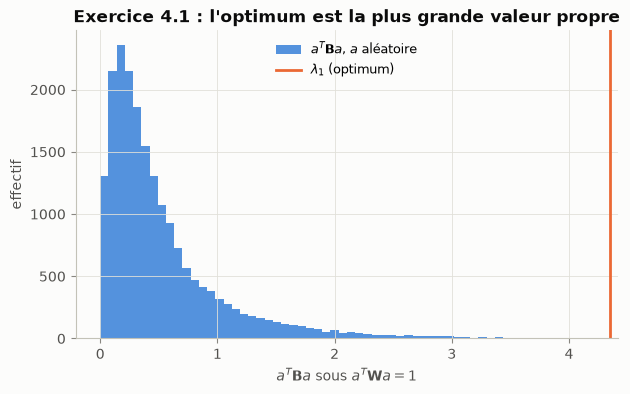

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(vals, bins=60, color=BLUE, alpha=0.8, label=r"$a^T\mathbf{B}a$, $a$ aléatoire")
ax.axvline(l1[-1], color=ORANGE, lw=2, label=r"$\lambda_1$ (optimum)")
ax.set_title("Exercice 4.1 : l'optimum est la plus grande valeur propre")
ax.set_xlabel(r"$a^T\mathbf{B}a$ sous $a^T\mathbf{W}a = 1$")
ax.set_ylabel("effectif")
ax.legend()
plt.show()

> **À retenir.** Le changement de variable $b = \mathbf{W}^{1/2}a$ (ou $b = \mathbf{L}^Ta$
> avec Cholesky) transforme la contrainte $a^T\mathbf{W}a = 1$ en $\|b\| = 1$ ; le
> problème devient la diagonalisation de la matrice symétrique
> $\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}$, et $a = \mathbf{W}^{-1/2}b$.

## Exercice 4.2 : LDA et moindres carrés à deux classes

**Énoncé.** On dispose de $x\in\mathbb{R}^p$ et d'une réponse à deux classes d'effectifs
$N_1, N_2$ ($N = N_1+N_2$), la cible étant codée $-N/N_1$ pour la classe 1 et $N/N_2$ pour la
classe 2.

(a) Montrer que la LDA classe en 2 si
$x^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) > \frac12(\hat\mu_2+\hat\mu_1)^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) - \log(N_2/N_1)$,
et en 1 sinon.

(b) On minimise $\sum_i(y_i-\beta_0-x_i^T\beta)^2$ (éq. (4.55)). Montrer que la solution
vérifie $\big[(N-2)\hat\Sigma + N\hat\Sigma_B\big]\beta = N(\hat\mu_2-\hat\mu_1)$ (éq. (4.56)),
où $\hat\Sigma_B = \frac{N_1N_2}{N^2}(\hat\mu_2-\hat\mu_1)(\hat\mu_2-\hat\mu_1)^T$.

(c) En déduire que $\hat\Sigma_B\beta$ est colinéaire à $\hat\mu_2-\hat\mu_1$, donc que
$\hat\beta \propto \hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1)$ (éq. (4.57)) : le coefficient des
moindres carrés est celui de la LDA à un facteur près.

(d) Montrer que ce résultat vaut pour tout codage (distinct) des deux classes.

(e) Trouver $\hat\beta_0$ et la fonction $\hat f(x) = \hat\beta_0 + x^T\hat\beta$. Montrer que
la règle « classer en 2 si $\hat f(x) > 0$ » ne coïncide avec la LDA que si $N_1 = N_2$.

### Notations

$\hat\mu_k$ est la moyenne de la classe $k$, $\bar x = (N_1\hat\mu_1 + N_2\hat\mu_2)/N$ la
moyenne globale, $d = \hat\mu_2 - \hat\mu_1$, et
$\hat\Sigma = \frac{1}{N-2}\sum_{k=1}^2\sum_{g_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^T$ la
covariance intra-classe. On suppose $\hat\Sigma$ inversible.

### (a) La règle LDA

Avec $\hat\pi_k = N_k/N$, la LDA classe en 2 si $\delta_2(x) > \delta_1(x)$, où
$\delta_k(x) = x^T\hat\Sigma^{-1}\hat\mu_k - \frac12\hat\mu_k^T\hat\Sigma^{-1}\hat\mu_k + \log\hat\pi_k$.
La différence vaut
$$\delta_2(x)-\delta_1(x) = x^T\hat\Sigma^{-1}d - \tfrac12\big(\hat\mu_2^T\hat\Sigma^{-1}\hat\mu_2 - \hat\mu_1^T\hat\Sigma^{-1}\hat\mu_1\big) + \log\frac{N_2}{N_1}.$$
Comme $\hat\Sigma^{-1}$ est symétrique, $\hat\mu_1^T\hat\Sigma^{-1}\hat\mu_2 = \hat\mu_2^T\hat\Sigma^{-1}\hat\mu_1$
et donc $(\hat\mu_2+\hat\mu_1)^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) = \hat\mu_2^T\hat\Sigma^{-1}\hat\mu_2 - \hat\mu_1^T\hat\Sigma^{-1}\hat\mu_1$
(les termes croisés se compensent). La condition $\delta_2 > \delta_1$ s'écrit donc
exactement comme annoncé. $\square$

### (b) Les équations normales

Annulons les dérivées partielles du critère (4.55).

- Par rapport à $\beta_0$ : $\sum_i(y_i-\beta_0-x_i^T\beta) = 0$, d'où
  $\beta_0 = \bar y - \bar x^T\beta$. Or $\sum_iy_i = N_1\cdot(-N/N_1) + N_2\cdot N/N_2 = 0$,
  donc $\bar y = 0$ et $\boxed{\beta_0 = -\bar x^T\beta}$.
- Par rapport à $\beta$ : $\sum_ix_i(y_i-\beta_0-x_i^T\beta) = 0$. En remplaçant $\beta_0$ :
  $\sum_ix_i\big(y_i - (x_i-\bar x)^T\beta\big) = 0$.

Dans cette dernière somme, on peut remplacer $x_i$ par $x_i - \bar x$ devant la
parenthèse, car $\sum_i\bar x\big(y_i-(x_i-\bar x)^T\beta\big) = \bar x\big(\sum_iy_i - (\sum_i(x_i-\bar x))^T\beta\big) = 0$.
On obtient
$$\underbrace{\sum_i(x_i-\bar x)(x_i-\bar x)^T}_{\mathbf{T}}\ \beta = \sum_i(x_i - \bar x)\,y_i = \sum_ix_iy_i.$$

**Le second membre.** Les $y_i$ étant constants par classe,
$$\sum_ix_iy_i = -\frac{N}{N_1}\sum_{g_i=1}x_i + \frac{N}{N_2}\sum_{g_i=2}x_i = -\frac{N}{N_1}N_1\hat\mu_1 + \frac{N}{N_2}N_2\hat\mu_2 = N(\hat\mu_2-\hat\mu_1).$$

**La matrice $\mathbf{T}$ (dispersion totale).** On écrit $x_i - \bar x = (x_i - \hat\mu_k) + (\hat\mu_k - \bar x)$
pour $g_i = k$ et on développe. Les termes croisés sont nuls car
$\sum_{g_i=k}(x_i-\hat\mu_k) = 0$ (définition de $\hat\mu_k$). Il reste
$$\mathbf{T} = \underbrace{\sum_k\sum_{g_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^T}_{=(N-2)\hat\Sigma} + \sum_kN_k(\hat\mu_k-\bar x)(\hat\mu_k-\bar x)^T.$$
Or $\hat\mu_1 - \bar x = \frac{N_2}{N}(\hat\mu_1-\hat\mu_2) = -\frac{N_2}{N}d$ et
$\hat\mu_2-\bar x = \frac{N_1}{N}d$, donc le second terme vaut
$$N_1\frac{N_2^2}{N^2}dd^T + N_2\frac{N_1^2}{N^2}dd^T = \frac{N_1N_2(N_1+N_2)}{N^2}dd^T = N\cdot\frac{N_1N_2}{N^2}dd^T = N\hat\Sigma_B.$$
D'où $\big[(N-2)\hat\Sigma + N\hat\Sigma_B\big]\beta = N(\hat\mu_2-\hat\mu_1)$. $\square$

### (c) Colinéarité avec la direction LDA

$\hat\Sigma_B\beta = \frac{N_1N_2}{N^2}d\,(d^T\beta)$ et $d^T\beta$ est un **scalaire** :
$\hat\Sigma_B\beta$ est donc colinéaire à $d$. L'équation (4.56) donne alors
$$(N-2)\hat\Sigma\beta = Nd - N\hat\Sigma_B\beta = \Big(N - \frac{N_1N_2}{N}d^T\beta\Big)d,$$
d'où $\hat\beta \propto \hat\Sigma^{-1}d = \hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1)$.

On peut même calculer le facteur : en cherchant $\hat\beta = \kappa\hat\Sigma^{-1}d$ et en
notant $\Delta^2 = d^T\hat\Sigma^{-1}d$ (carré de la distance de Mahalanobis entre les
centroïdes), (4.56) devient $\kappa\big[(N-2) + \frac{N_1N_2}{N}\Delta^2\big]d = Nd$, soit
$$\kappa = \frac{N}{N-2+\frac{N_1N_2}{N}\Delta^2} > 0.$$